In [1]:
#Here, we are using float64 everywhere: -
import numpy as np

def numerical_grad(f, x, eps=1e-6):
    g = np.zeros_like(x)
    for idx in np.ndindex(*x.shape):
        old = x[idx]
        x[idx] = old + eps; plus = f(x)
        x[idx] = old - eps; minus = f(x)
        x[idx] = old
        g[idx] = (plus - minus) / (2 * eps)
    return g

def rel_err(a, b):
    return np.max(np.abs(a - b) / np.maximum(1.0, np.abs(a) + np.abs(b)))

rng = np.random.default_rng(0)

In [31]:
#Before the running the cell, I am pridicting the shape of each of the array being mentioned below:] -
a = np.ones((3, 4))
print((a + np.arange(4)).shape) #The shape is -> (3 x 4)
print((a + np.arange(3).reshape(3, 1)).shape) # -> (3 x 4)
print((np.arange(3).reshape(3, 1) + np.arange(4).reshape(1, 4)).shape) # -> (3 x 4)
a + np.arange(3)    # this one fails: why? -> This is failing as the shape of the first is (4 x 3), (3, 4), and that of the other is (1 x 3), (3, 1), since as per the  rules of the brodcasting: -
#The comparision starts from the rightmost side, and nither of the parameter is 1 nor they are equal to each other.

(3, 4)
(3, 4)
(3, 4)


ValueError: operands could not be broadcast together with shapes (3,4) (3,) 

In [5]:
#This reverses broadcasting in the backward pass. Here, it is predicting the actual array, which after brodcasting has changed it's size.

def unbroadcast(grad, shape):
    while grad.ndim > len(shape):
        grad = grad.sum(axis=0)
    for i, s in enumerate(shape):
        if s == 1:
            grad = grad.sum(axis=i, keepdims=True)
    return grad

assert np.array_equal(unbroadcast(np.ones((2, 3)), (3,)), np.array([2., 2., 2.]))
assert np.array_equal(unbroadcast(np.ones((2, 3)), (2, 1)), np.array([[3.], [3.]]))
assert unbroadcast(np.ones((2, 3)), ()) == 6.0

In [6]:
print(unbroadcast(np.ones((2, 3)), (3,)))
print(unbroadcast(np.ones((2, 3)), (2, 1)))
print(unbroadcast(np.ones((2, 3)), ()))
print(unbroadcast(np.ones((2, 3)), (2, 3)).shape) #This is printing the shape.

[2. 2. 2.]
[[3.]
 [3.]]
6.0
(2, 3)


In [7]:
print("1. Extra leading dimensions:")
# Output grad shape: (2, 3), Original input shape: (3,)
# The first dimension (size 2) was added via broadcasting. We sum over axis 0.
grad = np.ones((2, 3))
print("Input gradient:\n", grad)
print("Unbroadcasted to (3,):", unbroadcast(grad, (3,)))

print("\n2. Stretched dimensions (size 1):")
# Output grad shape: (2, 3), Original input shape: (2, 1)
# The second dimension was stretched from 1 to 3. We sum over axis 1, keeping the dimension.
print("Unbroadcasted to (2, 1):\n", unbroadcast(grad, (2, 1)))

1. Extra leading dimensions:
Input gradient:
 [[1. 1. 1.]
 [1. 1. 1.]]
Unbroadcasted to (3,): [2. 2. 2.]

2. Stretched dimensions (size 1):
Unbroadcasted to (2, 1):
 [[3.]
 [3.]]


In [8]:
# ### Summary of Dimension Changes (Forward vs. Backward)

# | Case | Forward Pass (Broadcasting) | Backward Pass (Unbroadcasting) |
# | :--- | :--- | :--- |
# | **Case 1 (Extra leading)** | **Expands** dimension count: `(3,)` $\rightarrow$ `(2, 3)` | **Shrinks** dimension count: `(2, 3)` $\rightarrow$ `(3,)` by summing over `axis=0` |
# | **Case 2 (Stretched dimension)** | **Expands** axis size: `(2, 1)` $\rightarrow$ `(2, 3)` by repeating elements | **Shrinks** axis size: `(2, 3)` $\rightarrow$ `(2, 1)` by summing along `axis=1` |
# | **Case 3 (Fully collapsed/Scalar)** | **Reduces** to scalar: `(2, 3)` $\rightarrow$ `()` (e.g., total `sum`) | **Expands** back to original shape: `()` $\rightarrow$ `(2, 3)` by copying/distributing gradient to all elements |

In [20]:
#This is on gradients for vectorised operations: -

rng = np.random.default_rng(0)   # reseed, so the numbers repeat every time
A = rng.normal(size=(2, 3)); B = rng.normal(size=(3, 4)); dC = rng.normal(size=(2, 4))
L = lambda A_, B_: np.sum(dC * (A_ @ B_))

dA = dC @ B.T
dA_num = numerical_grad(lambda x: L(x, B), A.copy())
print("dA from formula:\n", dA)
print("dA from numerical check:\n", dA_num)
print("error:", rel_err(dA, dA_num))

dB = A.T @ dC
dB_num = numerical_grad(lambda x: L(A, x), B.copy())
print("dB from formula:\n", dB)
print("dB from numerical check:\n", dB_num)
print("error:", rel_err(dB, dB_num))

dA from formula:
 [[-0.11458704 -0.21359968 -1.63850996]
 [-1.28927437 -1.69203973  0.04991611]]
dA from numerical check:
 [[-0.11458704 -0.21359968 -1.63850996]
 [-1.28927437 -1.69203973  0.04991611]]
error: 4.7062992392099545e-11
dB from formula:
 [[-0.0180246   0.16794888  0.07861344  0.18166766]
 [ 0.30194602 -0.32601427 -0.46698125 -0.23087598]
 [ 0.02308641  0.79475348  0.24437384  0.90910854]]
dB from numerical check:
 [[-0.0180246   0.16794888  0.07861344  0.18166766]
 [ 0.30194602 -0.32601427 -0.46698125 -0.23087598]
 [ 0.02308641  0.79475348  0.24437384  0.90910854]]
error: 1.0424633378747217e-10


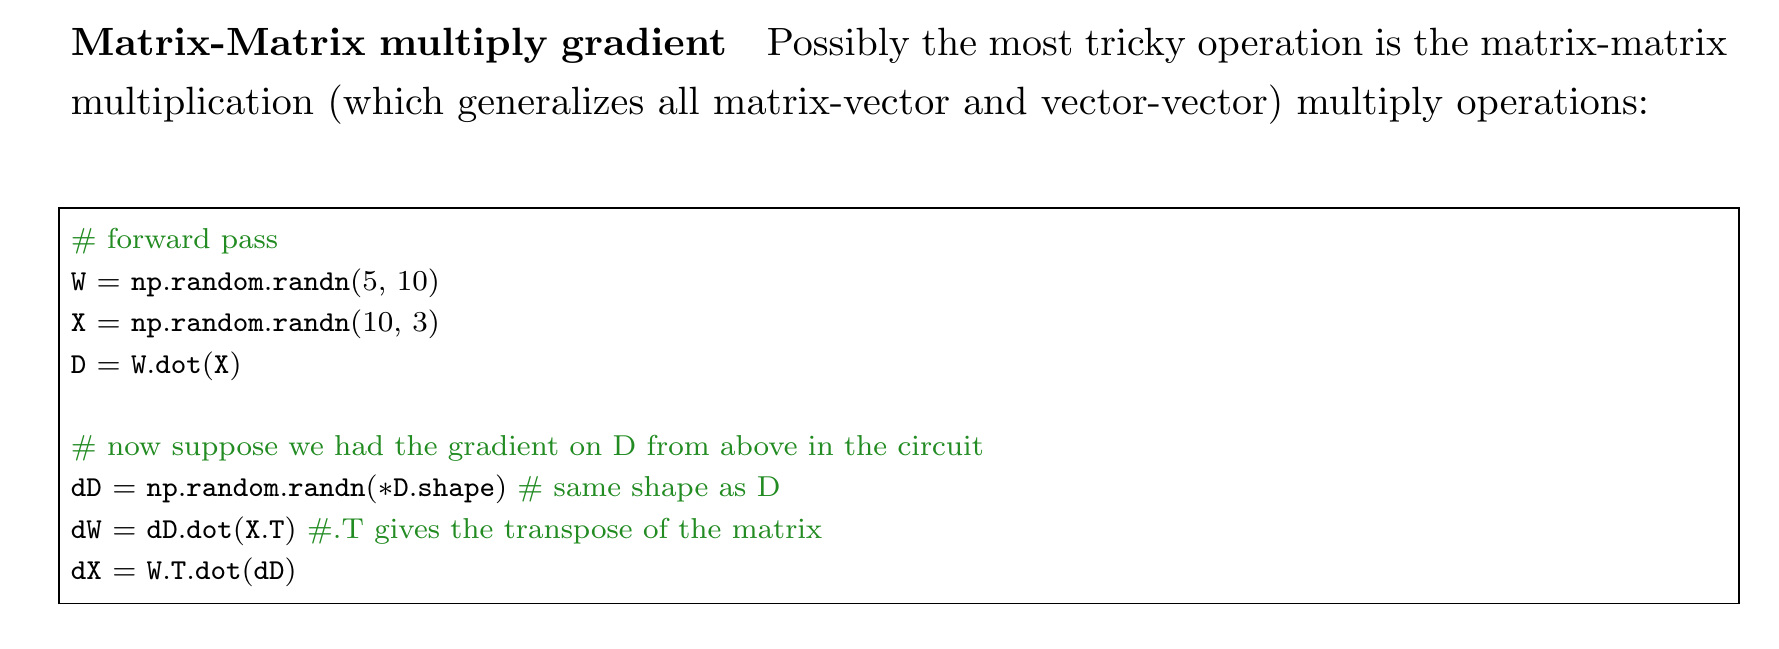

### Mathematical Summary of Matrix Gradients

For a fully connected layer with input $X \in \mathbb{R}^{N \times D}$, weights $W \in \mathbb{R}^{D \times M}$, and bias $b \in \mathbb{R}^{M}$:

$$Y = XW + b$$

Given the upstream loss gradient $\frac{\partial L}{\partial Y} = dY \in \mathbb{R}^{N \times M}$, the downstream gradients are computed as:

1. **Gradient with respect to Input ($X$):**
   $$\frac{\partial L}{\partial X} = dY \cdot W^T \quad \in \mathbb{R}^{N \times D}$$
   *Code implementation:* `dX = dY @ W.T`

2. **Gradient with respect to Weights ($W$):**
   $$\frac{\partial L}{\partial W} = X^T \cdot dY \quad \in \mathbb{R}^{D \times M}$$
   *Code implementation:* `dW = X.T @ dY`

3. **Gradient with respect to Bias ($b$):**
   $$\frac{\partial L}{\partial b} = \sum_{i=1}^{N} dY_{i, :} \quad \in \mathbb{R}^{M}$$
   *Code implementation:* `db = dY.sum(axis=0)` (this sums the gradients across the batch dimension to reverse the forward broadcast operation)

In [24]:
#Here, the same operations is being performed as it is being mentioned above in the notes shared: -
#We are basically doing the products of the matrices and checking for the dimensions and the size of the arrays, after the brodcasting: -

X = rng.normal(size=(5, 3)); W = rng.normal(size=(3, 4)); b = rng.normal(size=(4,))
dY = rng.normal(size=(5, 4))
loss = lambda X_, W_, b_: np.sum(dY * (X_ @ W_ + b_))
dX = dY @ W.T
dW = X.T @ dY
db = dY.sum(axis=0)                       # the bias gradient sums over the batch
assert dX.shape == X.shape and dW.shape == W.shape and db.shape == b.shape

print("The matrix dX\n", dX)
print("The matrix dW\n", dW)
print("The matrix db\n", db)

print("\n")

print(rel_err(dX, numerical_grad(lambda x: loss(x, W, b), X.copy())))
print(rel_err(dW, numerical_grad(lambda x: loss(X, x, b), W.copy())))
print(rel_err(db, numerical_grad(lambda x: loss(X, W, x), b.copy())))

The matrix dX
 [[ 4.42792384  1.45688085  0.55617307]
 [ 1.32305339  0.77318767  0.98802334]
 [ 6.56419352  3.49613347  4.52720596]
 [ 1.14240447  0.20133184  0.48446733]
 [ 0.66002218  0.36665188 -1.6221151 ]]
The matrix dW
 [[-2.14230285  1.82395078  0.58605917  0.26050801]
 [ 1.82198357 -2.53426319 -0.07674403 -0.78251152]
 [-0.05091416  0.29150981  1.71269654 -5.75530801]]
The matrix db
 [-0.57359419  6.46791916 -1.84397354 -1.64192919]


5.051424984748075e-10
6.206576641520911e-10
4.87551364123453e-10


### The Four Gradient Checks being done below: -

####Here $d_{out}$ is the gradient that is coming via all the previous layers before the final layer.

1. **ReLU:** Gradients are routed only to positive elements:
   $$\frac{\partial L}{\partial x} = d_{out} \cdot \mathbb{I}(x > 0)$$
2. **tanh:** Gradients are scaled by the derivative of tanh:
   $$\frac{\partial L}{\partial x} = d_{out} \cdot (1 - \tanh^2(x))$$
3. **Scaled Sum ($3 \cdot \sum x$):** Since every element is added up and multiplied by 3, the gradient is constant:
   $$\frac{\partial L}{\partial x} = 3.0$$
4. **Scaled Mean ($2 \cdot \text{mean}(x)$):** The sum is averaged across $N$ elements, distributing the gradient equally:
   $$\frac{\partial L}{\partial x} = \frac{2.0}{N}$$

**Imp - Here, x is a 2D NumPy array of shape (3, 4) containing random values drawn from a standard normal distribution (using rng.normal)**

####The mentioned below are two important things that is being covered in the section below: -

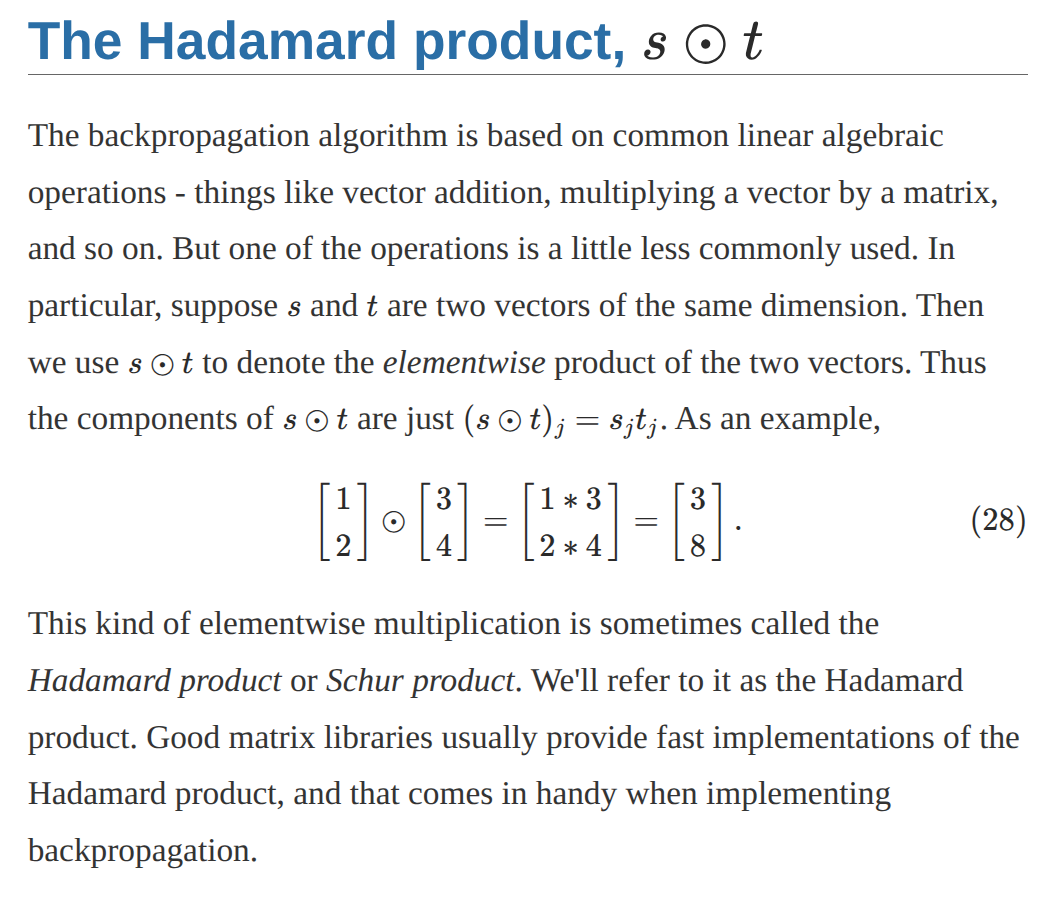

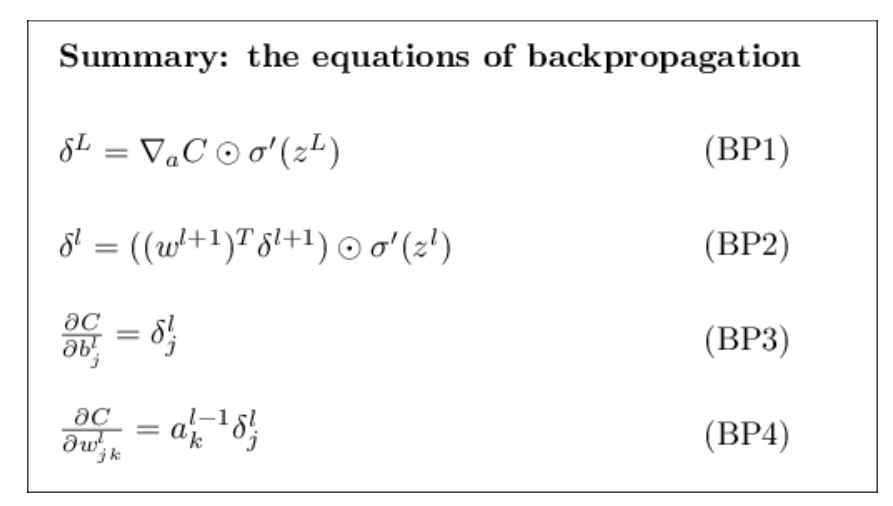

In [29]:
x = rng.normal(size=(3, 4)); dout = rng.normal(size=(3, 4))
# ReLU: gradient passes only where x > 0
print(rel_err(dout * (x > 0), numerical_grad(lambda t: np.sum(dout * np.maximum(t, 0)), x.copy())))
# tanh: 1 - tanh(x)^2
print(rel_err(dout * (1 - np.tanh(x) ** 2), numerical_grad(lambda t: np.sum(dout * np.tanh(t)), x.copy())))
# sum: the gradient is copied to every element
print(rel_err(np.ones_like(x) * 3.0, numerical_grad(lambda t: 3.0 * np.sum(t), x.copy())))
# mean: the gradient is divided by the number of elements
print(rel_err(np.ones_like(x) * 2.0 / x.size, numerical_grad(lambda t: 2.0 * np.mean(t), x.copy())))

1.1411153911191407e-10
1.1817669759439653e-10
6.988898348447898e-11
2.3296337081646357e-11


In [30]:
# This is the inspection of the variable `x`
print("Type of x:", type(x))
print("Shape of x:", x.shape)
print("Data type of x:", x.dtype)
print("\nValues inside x:")
display(x)

Type of x: <class 'numpy.ndarray'>
Shape of x: (3, 4)
Data type of x: float64

Values inside x:


array([[ 0.80471693,  0.85274847, -0.66768729,  0.16324401],
       [-0.83075196,  2.34580807, -0.70413956, -0.45307444],
       [-1.06583802, -0.34612128, -0.00587603,  0.76778914]])